# Лабораторная работа №1. Очистка и подготовка датасета

**Датасет:** [Walmart Dataset (Kaggle)](https://www.kaggle.com/datasets/yasserh/walmart-dataset)

### Задачи
1. Заполнить пропуски.
2. Удалить (обработать) выбросы.
3. Согласовать типы данных.
4. Провести проектирование признаков (feature engineering):
   - признаки на основе даты;
   - лаговые признаки (значения предыдущих периодов);
   - агрегации.
5. Масштабировать числовые признаки.
6. Закодировать категориальные признаки.

## Импорт библиотек

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid')

## Загрузка данных

In [3]:
df = pd.read_csv('data/Walmart.csv')
print(f'Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов')
df.head()

Размер датасета: 6435 строк, 8 столбцов


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.900,0,42.310,2.572,211.096,8.106
1,1,12-02-2010,1641957.440,1,38.510,2.548,211.242,8.106
2,1,19-02-2010,1611968.170,0,39.930,2.514,211.289,8.106
3,1,26-02-2010,1409727.590,0,46.630,2.561,211.320,8.106
4,1,05-03-2010,1554806.680,0,46.500,2.625,211.350,8.106


## Визуальный анализ

### Тепловая карта

Коэффициенты линейной корреляции Пирсона между числовыми признаками.

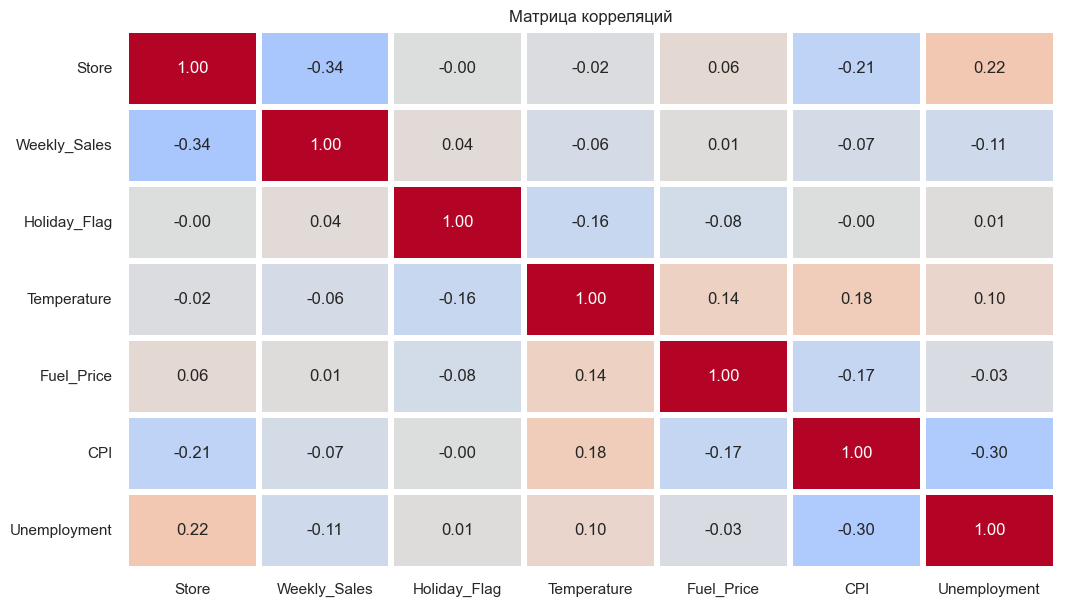

In [5]:
num = df.select_dtypes('number')

plt.figure(figsize=(12, 7))
sns.heatmap(num.corr(), annot=True, fmt='.2f', linewidths=3, cbar=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матрица корреляций')
plt.show()

### Распределения

Гистограммы непрерывных признаков с оценкой плотности. Линиями отмечены квартили, медиана, среднее и пороги отсечения выбросов $[Q_1 - 1.5 \cdot IQR;\ Q_3 + 1.5 \cdot IQR]$.

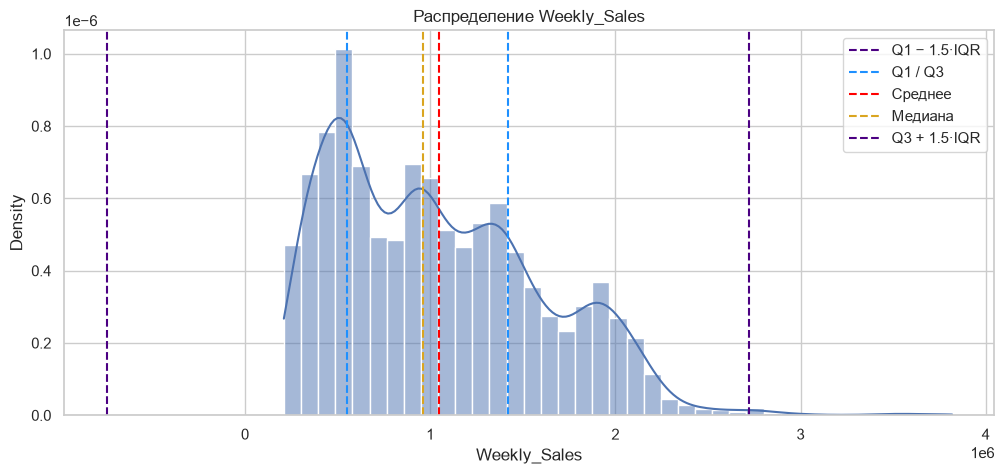

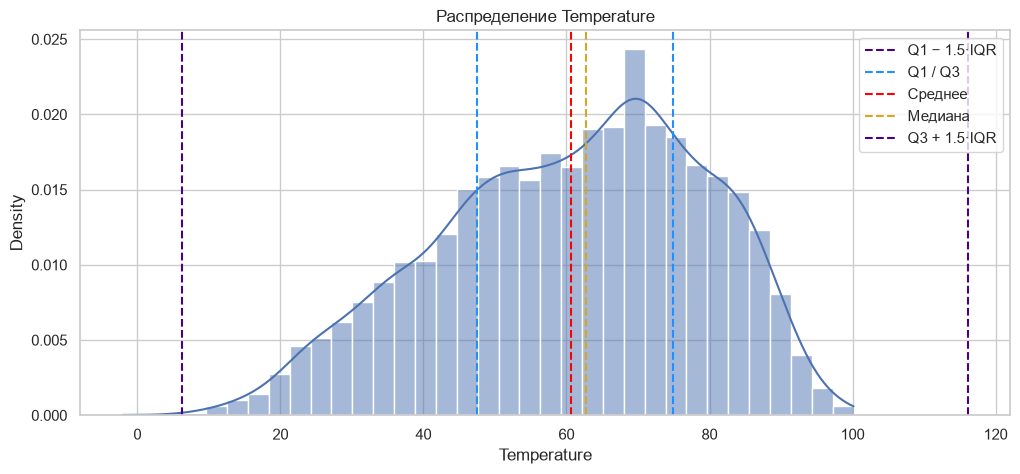

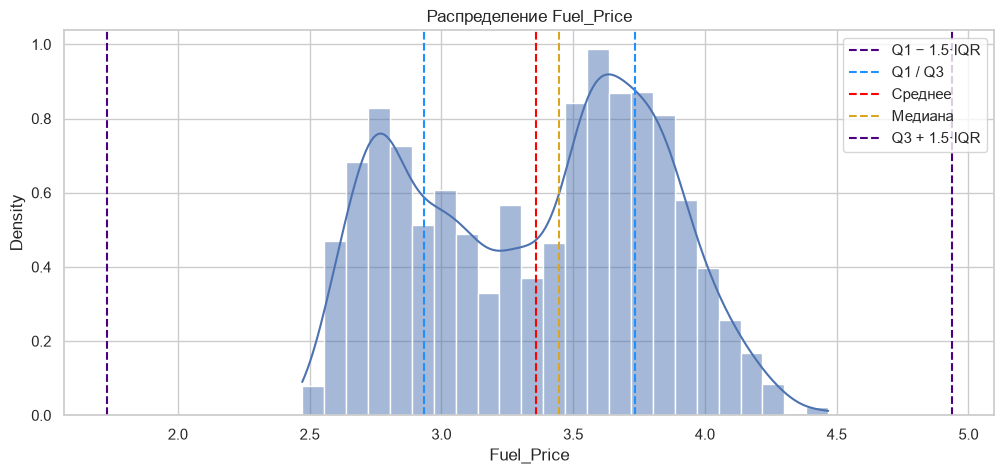

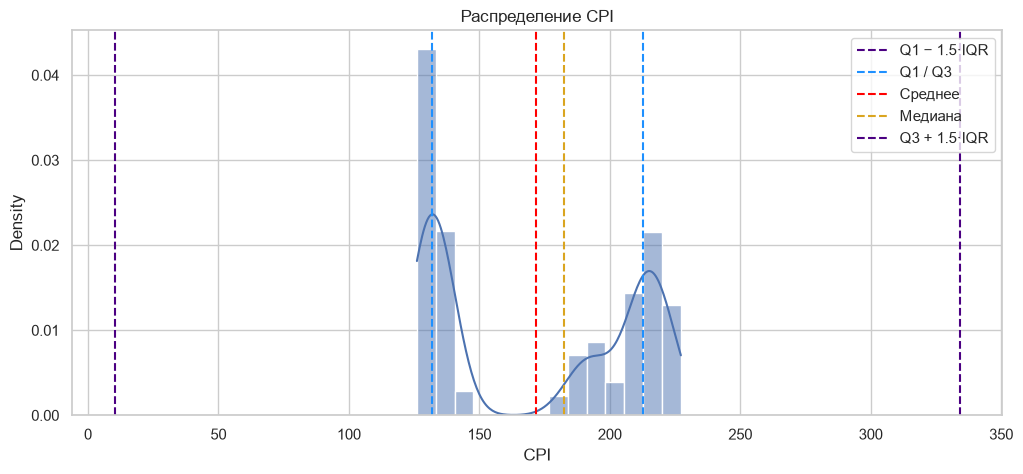

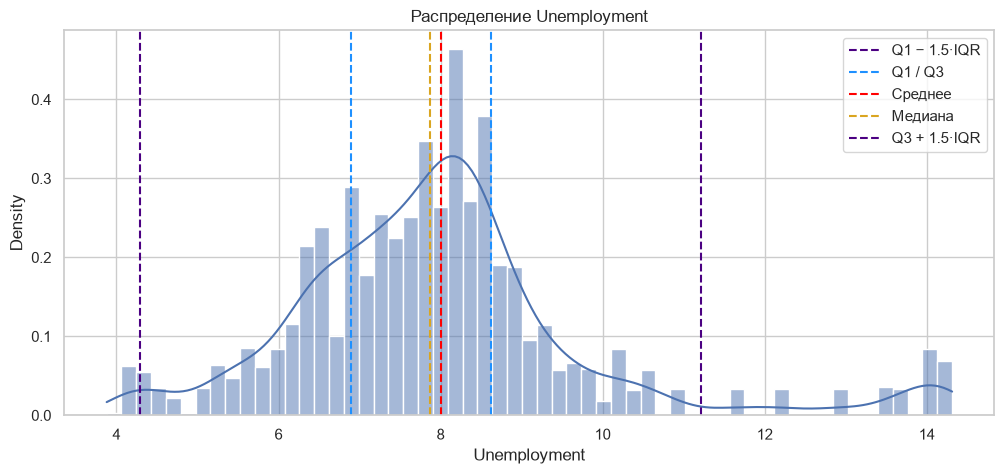

In [7]:
cont = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

for i in cont:
    q1, q3 = df[i].quantile([0.25, 0.75])
    iqr = q3 - q1
    plt.figure(i, figsize=(12, 5))
    sns.histplot(df[i], kde=True, stat='density')
    plt.axvline(q1 - 1.5 * iqr, color='indigo', ls='--', label='Q1 − 1.5·IQR')
    plt.axvline(q1, color='dodgerblue', ls='--', label='Q1 / Q3')
    plt.axvline(df[i].mean(), color='red', ls='--', label='Среднее')
    plt.axvline(df[i].median(), color='goldenrod', ls='--', label='Медиана')
    plt.axvline(q3, color='dodgerblue', ls='--')
    plt.axvline(q3 + 1.5 * iqr, color='indigo', ls='--', label='Q3 + 1.5·IQR')
    plt.title(f'Распределение {i}')
    plt.legend()
    plt.show()

## Поиск выбросов по IQR

Распределения признаков не нормальные, поэтому для поиска выбросов используем правило интерквартильного размаха. Выбросом считается значение за границами:

$$[Q_1 - 1.5 \cdot IQR;\ Q_3 + 1.5 \cdot IQR], \quad IQR = Q_3 - Q_1$$

`Store` и `Holiday_Flag` не проверяем — это категориальный и бинарный признаки.

Границы IQR считаем **отдельно для каждого магазина**, а не по всему датасету сразу:
- магазины различаются по объёму продаж почти в 10 раз — общие границы `Weekly_Sales` отмечали бы только пиковые недели крупных магазинов;
- `Temperature`, `Fuel_Price`, `CPI` и `Unemployment` — региональные показатели, и общие границы находили бы не аномалии, а различия между регионами.

In [6]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def iqr_outliers(s):
    low, high = iqr_bounds(s)
    return (s < low) | (s > high)


cont = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
other = [col for col in cont if col != 'Weekly_Sales']

### `Weekly_Sales` внутри каждого магазина

Ящики с усами продаж по каждому магазину. Точки за усами — выбросы внутри своего магазина.

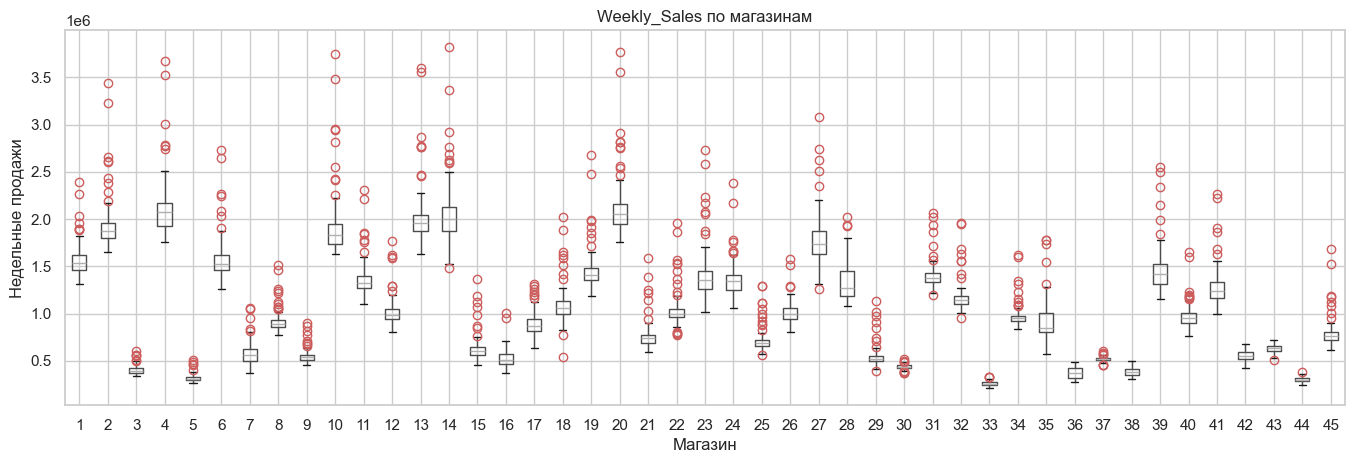

In [7]:
ax = df.boxplot(column='Weekly_Sales', by='Store', figsize=(16, 5),
                flierprops=dict(markeredgecolor='indianred'))
plt.suptitle('')
ax.set_title('Weekly_Sales по магазинам')
ax.set_xlabel('Магазин')
ax.set_ylabel('Недельные продажи')
plt.show()

In [9]:
g = df.groupby('Store')['Weekly_Sales']
q1 = g.transform(lambda x: x.quantile(0.25))
q3 = g.transform(lambda x: x.quantile(0.75))
iqr = q3 - q1

sales_out = (df['Weekly_Sales'] < q1 - 1.5 * iqr) | (df['Weekly_Sales'] > q3 + 1.5 * iqr)
print('Выбросов Weekly_Sales внутри магазинов:', sales_out.sum())
print('выше верхней границы:', (df['Weekly_Sales'] > q3 + 1.5 * iqr).sum())
print('ниже нижней границы:', (df['Weekly_Sales'] < q1 - 1.5 * iqr).sum())

Выбросов Weekly_Sales внутри магазинов: 300
выше верхней границы: 279
ниже нижней границы: 21


Сводная таблица по магазинам: границы IQR каждого магазина и количество выбросов сверху и снизу.

In [10]:
stores = df.groupby('Store')['Weekly_Sales'].agg(Медиана='median', Минимум='min', Максимум='max')
stores['Нижняя граница'] = stores.index.map(lambda s: iqr_bounds(df.loc[df['Store'] == s, 'Weekly_Sales'])[0])
stores['Верхняя граница'] = stores.index.map(lambda s: iqr_bounds(df.loc[df['Store'] == s, 'Weekly_Sales'])[1])
stores['Ниже'] = (df['Weekly_Sales'] < q1 - 1.5 * iqr).groupby(df['Store']).sum()
stores['Выше'] = (df['Weekly_Sales'] > q3 + 1.5 * iqr).groupby(df['Store']).sum()
stores['Всего выбросов'] = stores['Ниже'] + stores['Выше']

with pd.option_context('display.max_rows', None):
    display(stores)

,Медиана,Минимум,Максимум,Нижняя граница,Верхняя граница,Ниже,Выше,Всего выбросов
Store,,,,,,,,
1,1534849.640,1316899.310,2387950.200,1222923.680,1850073.040,0,7,7
2,1879107.310,1650394.440,3436007.680,1573361.793,2187065.372,0,9,9
3,395107.350,339597.380,605990.410,288512.462,500107.482,0,6,6
4,2073951.380,1762539.300,3676388.980,1561470.360,2543180.040,0,6,6
5,310338.170,260636.710,507900.070,241949.130,382607.450,0,5,5
6,1524390.070,1261253.180,2727575.180,1203298.980,1877560.820,0,7,7
7,557166.350,372673.610,1059715.270,312238.440,806677.680,0,5,5
8,893399.770,772539.120,1511641.090,746231.968,1038694.548,0,11,11
9,536537.640,452905.220,905324.680,426694.005,640221.245,0,8,8


Выведем строки с выбросами отдельно для кажадого магазина:

In [12]:
df_out = df[sales_out].assign(Граница=np.where(df.loc[sales_out, 'Weekly_Sales'] > q3[sales_out], 'выше', 'ниже'))

for store, part in df_out.groupby('Store'):
    low, high = iqr_bounds(df.loc[df['Store'] == store, 'Weekly_Sales'])
    print(f'Магазин {store}: {len(part)} выбросов, границы [{low:,.0f}; {high:,.0f}]')
    display(part[['Date', 'Weekly_Sales', 'Граница', 'Holiday_Flag', 'Temperature']])

Магазин 1: 7 выбросов, границы [1,222,924; 1,850,073]


,Date,Weekly_Sales,Граница,Holiday_Flag,Temperature
42,26-11-2010,1955624.110,выше,1,64.520
45,17-12-2010,1891034.930,выше,0,49.840
46,24-12-2010,2387950.200,выше,0,52.330
94,25-11-2011,2033320.660,выше,1,60.140
97,16-12-2011,1881176.670,выше,0,51.630
98,23-12-2011,2270188.990,выше,0,47.960
113,06-04-2012,1899676.880,выше,0,70.430


Магазин 2: 9 выбросов, границы [1,573,362; 2,187,065]


,Date,Weekly_Sales,Граница,Holiday_Flag,Temperature
185,26-11-2010,2658725.290,выше,1,62.980
187,10-12-2010,2378726.550,выше,0,45.500
188,17-12-2010,2609166.750,выше,0,47.550
189,24-12-2010,3436007.680,выше,0,49.970
237,25-11-2011,2614202.300,выше,1,56.360
239,09-12-2011,2290549.320,выше,0,41.760
240,16-12-2011,2432736.520,выше,0,50.130
241,23-12-2011,3224369.800,выше,0,46.660
249,17-02-2012,2196688.460,выше,0,43.820


Магазин 3: 6 выбросов, границы [288,512; 500,107]


...

,Date,Weekly_Sales,Граница,Holiday_Flag,Temperature
6105,30-12-2011,505405.850,ниже,1,41.830


Магазин 44: 1 выбросов, границы [229,798; 374,022]


,Date,Weekly_Sales,Граница,Holiday_Flag,Temperature
6247,23-12-2011,376233.890,выше,0,24.760


Магазин 45: 8 выбросов, границы [604,465; 920,002]


,Date,Weekly_Sales,Граница,Holiday_Flag,Temperature
6334,26-11-2010,1182500.160,выше,1,46.150
6336,10-12-2010,1002364.340,выше,0,30.540
6337,17-12-2010,1123282.850,выше,0,30.510
6338,24-12-2010,1682862.030,выше,0,30.590
6386,25-11-2011,1170672.940,выше,1,48.710
6388,09-12-2011,957155.310,выше,0,46.570
6389,16-12-2011,1078905.680,выше,0,39.930
6390,23-12-2011,1521957.990,выше,0,42.270


### Остальные признаки внутри каждого магазина

Проверим остальные непрерывные признаки тем же способом — с границами IQR, рассчитанными отдельно для каждого магазина.

In [13]:
rows = []
for col in other:
    by_store = df.groupby('Store')[col].transform(iqr_outliers)
    rows.append({'Признак': col,
                 'Выбросов': by_store.sum(),
                 'Магазинов с выбросами': df.loc[by_store, 'Store'].nunique()})

pd.DataFrame(rows).set_index('Признак')

,Выбросов,Магазинов с выбросами
Признак,,
Temperature,0,0
Fuel_Price,0,0
CPI,0,0
Unemployment,32,5


**Вывод.** Внутри каждого магазина у признаков `Temperature`, `Fuel_Price` и `CPI` **выбросов нет**.

Для `Unemployment` IQR внутри магазина нашёл несколько значений — рассмотрим их подробнее.

In [14]:
rows = []
for store, part in df.groupby('Store'):
    low, high = iqr_bounds(part['Unemployment'])
    out = part[(part['Unemployment'] < low) | (part['Unemployment'] > high)]
    if len(out):
        rows.append({'Магазин': store,
                     'Выбросов': len(out),
                     'Сторона': 'выше' if out['Unemployment'].iloc[0] > high else 'ниже',
                     'Нижняя граница': low,
                     'Верхняя граница': high,
                     'Значение выброса': out['Unemployment'].iloc[0],
                     'Первая неделя': out['Date'].iloc[0],
                     'Последняя неделя': out['Date'].iloc[-1],
                     'Безработица в начале периода': part['Unemployment'].iloc[0],
                     'Безработица в конце периода': part['Unemployment'].iloc[-1]})

unemp_out = pd.DataFrame(rows).set_index('Магазин')
unemp_out

,Выбросов,Сторона,Нижняя граница,Верхняя граница,Значение выброса,Первая неделя,Последняя неделя,Безработица в начале периода,Безработица в конце периода
Магазин,,,,,,,,,
1,4,ниже,6.613,8.573,6.573,05-10-2012,26-10-2012,8.106,6.573
17,4,ниже,5.846,7.331,5.527,05-10-2012,26-10-2012,6.548,5.527
20,8,выше,6.622,8.002,8.187,05-02-2010,26-03-2010,8.187,7.293
25,8,выше,6.622,8.002,8.187,05-02-2010,26-03-2010,8.187,7.293
35,8,выше,8.418,9.127,9.262,05-02-2010,26-03-2010,9.262,8.665


**Вывод.** Выбросы `Unemployment` внутри магазинов — **это норма, а не ошибка данных**:
- они есть только у 5 магазинов и приходятся либо на **первый квартал 2010 года** (магазины 20, 25, 35 — самая высокая безработица за период), либо на **последний квартал 2012 года** (магазины 1, 17 — самая низкая);
- внутри квартала значение не меняется: безработица обновляется раз в квартал, поэтому один «выброс» повторяется 4–8 недель подряд;
- безработица в этих регионах плавно снижалась в течение всего периода, и IQR помечает крайние точки этого **тренда**.

## Обработка выбросов

Большинство найденных выбросов `Weekly_Sales` объясняются календарём (Black Friday, недели перед Рождеством, Пасха, День святого Валентина, Labor Day, спад после праздников) или устойчивыми особенностями отдельных магазинов, которые повторяются каждый год. Это **допустимые** выбросы — реальное поведение продаж, их оставляем.

Отдельно проверим, как каждая неделя магазина отличается от соседних недель и от того, как в эту же дату изменились продажи остальных магазинов. Выделяются две одиночные недели:
- **02.09.2011 у магазина 18** — продажи упали почти вдвое (на 48% ниже соседних недель) и на следующей неделе вернулись к норме;

Эти отклонения:
- не объясняются праздником (`Holiday_Flag = 0`);
- не повторяются у этих магазинов в ту же неделю в другие годы;
- не проявляются в такой степени у остальных магазинов в эту дату;
- не объясняются ни одним признаком датасета.

Считаем их **шумом**.

In [15]:
noise = pd.DataFrame([
    (18, '02-09-2011')
], columns=['Store', 'Date'])

df.merge(noise, on=['Store', 'Date'], how='inner')

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,18,02-09-2011,540922.940,0,68.230,3.784,136.244,8.890


Посмотрим на эту неделю вместе с соседними, чтобы убедиться в резком одиночном отклонении:

In [16]:
for store, date in noise.itertuples(index=False):
    part = df[df['Store'] == store].reset_index(drop=True)
    i = part.index[part['Date'] == date][0]
    around = part.loc[max(i - 2, 0):i + 2, ['Date', 'Weekly_Sales']]
    print(f'Магазин {store}, {date}:')
    print(around.to_string(index=False), end='\n\n')

Магазин 18, 02-09-2011:
      Date  Weekly_Sales
19-08-2011    932679.790
26-08-2011   1147906.460
02-09-2011    540922.940
09-09-2011    951549.610
16-09-2011    845715.370



Строки не удаляем, а заменяем значение `Weekly_Sales` оценкой по соседям — так временной ряд каждого магазина остаётся непрерывным (это важно для лаговых признаков):

$$\text{новое значение} = \overline{x}_{\text{след. 5 недель}} \cdot k_{\text{рынка}}$$

где $\overline{x}_{\text{след. 5 недель}}$ — средние продажи магазина за следующие 5 недель, а $k_{\text{рынка}}$ — медиана по остальным магазинам отношения продаж этой недели к их среднему за следующие 5 недель.

In [18]:
sales = (df.assign(Date=pd.to_datetime(df['Date'], format='%d-%m-%Y'))
           .pivot(index='Date', columns='Store', values='Weekly_Sales'))

for store, date in noise.itertuples(index=False):
    i = sales.index.get_loc(pd.to_datetime(date, format='%d-%m-%Y'))
    next5 = sales.iloc[i + 1:i + 6].mean()
    market = (sales.iloc[i] / next5).drop(store).median()
    new_value = next5[store] * market

    mask = (df['Store'] == store) & (df['Date'] == date)
    print(f'Магазин {store}, {date}')
    print(f'было:                         {df.loc[mask, "Weekly_Sales"].iloc[0]:,.0f}')
    print(f'среднее следующих 5 недель:   {next5[store]:,.0f}')
    print(f'коэффициент рынка:            {market:.3f}')
    print(f'стало:                        {new_value:,.0f}', end='\n\n')

    df.loc[mask, 'Weekly_Sales'] = new_value

Магазин 18, 02-09-2011
было:                         933,606
среднее следующих 5 недель:   903,485
коэффициент рынка:            1.033
стало:                        933,606



## Согласование типов данных

При загрузке CSV pandas определяет типы автоматически, и не все они соответствуют смыслу признаков:

| Признак | Тип после загрузки | Смысл | Нужный тип |
|---|---|---|---|
| `Store` | `int64` | номер магазина — метка, а не количество | `category` |
| `Date` | `str` | дата недели продаж | `datetime64` |
| `Holiday_Flag` | `int64` | есть праздник или нет | `bool` |

Остальные признаки (`Weekly_Sales`, `Temperature`, `Fuel_Price`, `CPI`, `Unemployment`) — непрерывные числа, тип `float64` для них правильный.

In [19]:
df.dtypes

Store             int64
Date                str
Weekly_Sales    float64
Holiday_Flag      int64
Temperature     float64
Fuel_Price      float64
CPI             float64
Unemployment    float64
dtype: object

In [20]:
df['Store'] = df['Store'].astype('category')
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df['Holiday_Flag'] = df['Holiday_Flag'].astype(bool)

**Вывод.** `Store` переведён в категориальный тип, `Date` — в дату, `Holiday_Flag` — в логический тип. Объём памяти, занимаемый датасетом, уменьшился. Все даты приходятся на пятницу, то есть `Date` — это день, которым заканчивается неделя продаж.

## Проектирование признаков

### Признаки на основе даты

Модель не может использовать дату напрямую — для неё это просто уникальная метка. Разложим `Date` на составляющие календаря:

| Признак | Значения | Что даёт модели |
|---|---|---|
| `Year` | 2010–2012 | общий уровень продаж по годам |
| `Month` | 1–12 | сезонность: высокий декабрь, низкий январь |
| `Quarter` | 1–4 | более грубая сезонность |
| `WeekOfYear` | 1–52 | точное положение недели в году (Black Friday, предрождественские недели) |
| `DayOfMonth` | 1–31 | начало или конец месяца |

День недели не создаём: все даты приходятся на пятницу, у такого признака мощность была бы 1.

Предварительно отсортируем данные по магазину и дате — это понадобится для лаговых признаков.

In [21]:
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['DayOfMonth'] = df['Date'].dt.day

date_features = ['Year', 'Month', 'Quarter', 'WeekOfYear', 'DayOfMonth']
df[['Store', 'Date'] + date_features].head(10)

,Store,Date,Year,Month,Quarter,WeekOfYear,DayOfMonth
0,1,2010-02-05,2010,2,1,5,5
1,1,2010-02-12,2010,2,1,6,12
2,1,2010-02-19,2010,2,1,7,19
3,1,2010-02-26,2010,2,1,8,26
4,1,2010-03-05,2010,3,1,9,5
5,1,2010-03-12,2010,3,1,10,12
6,1,2010-03-19,2010,3,1,11,19
7,1,2010-03-26,2010,3,1,12,26
8,1,2010-04-02,2010,4,2,13,2
9,1,2010-04-09,2010,4,2,14,9


Проверим диапазоны и мощность новых признаков:

In [22]:
df[date_features].agg(['min', 'max', 'nunique']).T

,min,max,nunique
Year,2010,2012,3
Month,1,12,12
Quarter,1,4,4
WeekOfYear,1,52,52
DayOfMonth,1,31,31


### Циклические признаки

$$p_{sin} = \sin\left(\frac{2\pi p}{\max p}\right), \quad p_{cos} = \cos\left(\frac{2\pi p}{\max p}\right)$$


In [23]:
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)
df['Week_sin'] = np.sin(2 * np.pi * df['WeekOfYear'] / 52)
df['Week_cos'] = np.cos(2 * np.pi * df['WeekOfYear'] / 52)

cyclic_features = ['Month_sin', 'Month_cos', 'Week_sin', 'Week_cos']
df[['Date', 'Month', 'WeekOfYear'] + cyclic_features].drop_duplicates('Date').head(10)

,Date,Month,WeekOfYear,Month_sin,Month_cos,Week_sin,Week_cos
0,2010-02-05,2,5,0.866,0.500,0.568,0.823
1,2010-02-12,2,6,0.866,0.500,0.663,0.749
2,2010-02-19,2,7,0.866,0.500,0.749,0.663
3,2010-02-26,2,8,0.866,0.500,0.823,0.568
4,2010-03-05,3,9,1.000,0.000,0.885,0.465
5,2010-03-12,3,10,1.000,0.000,0.935,0.355
6,2010-03-19,3,11,1.000,0.000,0.971,0.239
7,2010-03-26,3,12,1.000,0.000,0.993,0.121
8,2010-04-02,4,13,0.866,-0.500,1.000,-0.000
9,2010-04-09,4,14,0.866,-0.500,0.993,-0.121


### Индикаторы праздников

`Holiday_Flag` отмечает 4 праздника: Super Bowl, Labor Day, Thanksgiving и Christmas. Но Christmas отмечен на неделе **после** Рождества, когда продажи уже падают, а рост продаж между Black Friday и Рождеством флагом не описан.

Посмотрим, как меняются продажи в ноябре–декабре. Чтобы сравнивать магазины разного размера, делим продажи каждого магазина на его медиану и берём медиану по всем магазинам:

In [26]:
season = df[(df['Month'] >= 11) | ((df['Month'] == 1) & (df['DayOfMonth'] <= 14))]
season_ratio = (season['Weekly_Sales'] / df.groupby('Store', observed=True)['Weekly_Sales'].transform('median')[season.index])

(season.assign(Ratio=season_ratio)
       .groupby('Date')
       .agg(WeekOfYear=('WeekOfYear', 'first'), Holiday_Flag=('Holiday_Flag', 'first'), Ratio=('Ratio', 'median'))
       .round(2))

,WeekOfYear,Holiday_Flag,Ratio
Date,,,
2010-11-05,44,False,1.000
2010-11-12,45,False,1.000
2010-11-19,46,False,0.980
2010-11-26,47,True,1.410
2010-12-03,48,False,1.060
2010-12-10,49,False,1.160
2010-12-17,50,False,1.310
2010-12-24,51,False,1.760
2010-12-31,52,True,0.880


**Вывод.** В обоих годах картина одинаковая:
- неделя Black Friday — всплеск (×1,4), она уже отмечена `Holiday_Flag`;
- после неё продажи растут каждую неделю (×1,06 → ×1,2 → ×1,3) и достигают пика на **неделе перед Рождеством** (×1,7) — этот пик флагом не отмечен;
- неделя после Рождества (её отмечает `Holiday_Flag`) — спад ниже обычного уровня.

Создадим два индикатора:

| Признак | Что это |
|---|---|
| `Is_HolidaySeason` | праздничный сезон: недели от Black Friday до Рождества включительно — период роста продаж |
| `Is_PreChristmas` | неделя перед Рождеством — пик продаж года |

Оба признака считаются только по календарю, без использования продаж, поэтому утечки данных нет.

In [24]:
def days_to(holiday, dates):
    return (dates.dt.year.map(holiday) - dates).dt.days


def black_friday(year):
    nov1 = pd.Timestamp(year, 11, 1)
    thanksgiving = nov1 + pd.Timedelta(days=(3 - nov1.weekday()) % 7 + 21)
    return thanksgiving + pd.Timedelta(days=1)


to_christmas = days_to(lambda y: pd.Timestamp(y, 12, 25), df['Date'])
from_black_friday = -days_to(black_friday, df['Date'])

df['Is_HolidaySeason'] = ((from_black_friday >= 0) & (to_christmas >= 1)).astype(int)
df['Is_PreChristmas'] = to_christmas.between(1, 7).astype(int)

holiday_features = ['Is_HolidaySeason', 'Is_PreChristmas']
df[df[holiday_features].any(axis=1)].drop_duplicates('Date')[['Date', 'WeekOfYear', 'Holiday_Flag'] + holiday_features]

,Date,WeekOfYear,Holiday_Flag,Is_HolidaySeason,Is_PreChristmas
42,2010-11-26,47,True,1,0
43,2010-12-03,48,False,1,0
44,2010-12-10,49,False,1,0
45,2010-12-17,50,False,1,0
46,2010-12-24,51,False,1,1
94,2011-11-25,47,True,1,0
95,2011-12-02,48,False,1,0
96,2011-12-09,49,False,1,0
97,2011-12-16,50,False,1,0
98,2011-12-23,51,False,1,1


In [25]:
lags = [1, 2, 3, 4]

for lag in lags:
    df[f'Sales_lag_{lag}'] = df.groupby('Store', observed=True)['Weekly_Sales'].shift(lag)

lag_features = [f'Sales_lag_{lag}' for lag in lags]
df.loc[df['Store'] == 1, ['Store', 'Date', 'Weekly_Sales'] + lag_features].head(6)

,Store,Date,Weekly_Sales,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_4
0,1,2010-02-05,1643690.900,NaN,NaN,NaN,NaN
1,1,2010-02-12,1641957.440,1643690.900,NaN,NaN,NaN
2,1,2010-02-19,1611968.170,1641957.440,1643690.900,NaN,NaN
3,1,2010-02-26,1409727.590,1611968.170,1641957.440,1643690.900,NaN
4,1,2010-03-05,1554806.680,1409727.590,1611968.170,1641957.440,1643690.900
5,1,2010-03-12,1439541.590,1554806.680,1409727.590,1611968.170,1641957.440


Лаги создают пропуски: у первых $N$ недель каждого магазина нет прошлого значения.

In [26]:
pd.DataFrame({'Пропусков': df[lag_features].isna().sum(),
              'Процент пропусков': df[lag_features].isna().mean() * 100})

,Пропусков,Процент пропусков
Sales_lag_1,45,0.699
Sales_lag_2,90,1.399
Sales_lag_3,135,2.098
Sales_lag_4,180,2.797


### Агрегации

Агрегация — показатель, посчитанный по группе значений.

| Признак | Как считается | Что даёт модели |
|---|---|---|
| `Sales_roll_std_4` | стандартное отклонение продаж за 4 прошлые недели | стабильность магазина: при маленьком разбросе лагам можно доверять, при большом (например, после праздников) — нет |
| `Sales_roll_mean_12` | среднее продаж за 12 прошлых недель  | «нормальный» уровень продаж магазина на длинном отрезке, сглаживает всплески отдельных недель, которые видят лаги |

Окно считаем по сдвинутому ряду (`shift(1)`), чтобы продажи текущей недели не попали в признак — иначе модель «подсмотрит» ответ. Среднее за 4 недели не создаём: оно в точности равно среднему `Sales_lag_1`…`Sales_lag_4`.

Для `Sales_roll_mean_12` задаём `min_periods=4`: в начале ряда окно содержит от 4 до 12 недель. Так признак не создаёт новых пропусков сверх тех, что уже есть у лагов.

In [28]:
past_sales = df.groupby('Store', observed=True)['Weekly_Sales'].shift(1)
by_store = past_sales.groupby(df['Store'], observed=True)

df['Sales_roll_std_4'] = by_store.transform(lambda s: s.rolling(4).std())
df['Sales_roll_mean_12'] = by_store.transform(lambda s: s.rolling(12, min_periods=4).mean())

agg_features = ['Sales_roll_std_4', 'Sales_roll_mean_12']
df.loc[df['Store'] == 1, ['Date', 'Weekly_Sales'] + lag_features + agg_features].head(8)

,Date,Weekly_Sales,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_4,Sales_roll_std_4,Sales_roll_mean_12
0,2010-02-05,1643690.900,NaN,NaN,NaN,NaN,NaN,NaN
1,2010-02-12,1641957.440,1643690.900,NaN,NaN,NaN,NaN,NaN
2,2010-02-19,1611968.170,1641957.440,1643690.900,NaN,NaN,NaN,NaN
3,2010-02-26,1409727.590,1611968.170,1641957.440,1643690.900,NaN,NaN,NaN
4,2010-03-05,1554806.680,1409727.590,1611968.170,1641957.440,1643690.900,112353.415,1576836.025
5,2010-03-12,1439541.590,1554806.680,1409727.590,1611968.170,1641957.440,103135.003,1572430.156
6,2010-03-19,1472515.790,1439541.590,1554806.680,1409727.590,1611968.170,95360.051,1550282.062
7,2010-03-26,1404429.920,1472515.790,1439541.590,1554806.680,1409727.590,62599.457,1539172.594


### Обработка пропусков

В исходных данных пропусков не было, они появились после создания лагов и скользящих агрегаций.

**Строки с пропусками удаляем.** Это первые 4 недели каждого магазина (05.02.2010 – 26.02.2010) — 180 строк, 2,8% данных. Недели обычные, без праздничных пиков, и те же недели года остаются в данных за 2011 и 2012 годы.

In [29]:
rows_before = len(df)
df = df.dropna(subset=lag_features + agg_features).reset_index(drop=True)

print(f'Удалено строк: {rows_before - len(df)}')
print(f'Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов')
print(f'Период: {df["Date"].min().date()} — {df["Date"].max().date()}')
print('Недель на магазин:', df.groupby('Store', observed=True).size().unique())

Удалено строк: 180
Размер датасета: 6255 строк, 25 столбцов
Период: 2010-03-05 — 2012-10-26
Недель на магазин: [139]


## Масштабирование числовых признаков


Используем **робастную стандартизацию**:

$$x' = \frac{x - Me}{IQR}, \quad IQR = Q_3 - Q_1$$

Распределения признаков не нормальные, а у продаж есть допустимые выбросы (праздничные недели), которые мы оставили. Медиана и интерквартильный размах к выбросам не чувствительны, в отличие от среднего и стандартного отклонения (z-нормализация) или минимума и максимума (min-max нормализация).

**Какие признаки масштабируем** — числовые: погодные и экономические показатели, лаги и агрегаты продаж, числовые признаки даты.

**Какие не масштабируем:**
- `Store` — категориальный, его закодируем на следующем шаге;
- `Holiday_Flag`, `Is_HolidaySeason`, `Is_PreChristmas` — бинарные 0/1;
- `Month_sin`, `Month_cos`, `Week_sin`, `Week_cos` — уже в диапазоне [−1; 1];
- `Weekly_Sales` — целевая переменная, оставляем в долларах;
- `Date` — служебный столбец, в модель не подаётся.

In [35]:
scale_features = (['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']
                  + lag_features + agg_features
                  + ['Year', 'Month', 'Quarter', 'WeekOfYear', 'DayOfMonth'])

df[scale_features].agg(['min', 'median', 'max']).T

,min,median,max
Temperature,-2.060,63.440,100.140
Fuel_Price,2.513,3.476,4.468
CPI,126.064,182.659,227.233
Unemployment,3.879,7.866,14.313
Sales_lag_1,209986.250,959229.090,3818686.450
Sales_lag_2,209986.250,960115.560,3818686.450
Sales_lag_3,209986.250,960476.100,3818686.450
Sales_lag_4,209986.250,960476.100,3818686.450
Sales_roll_std_4,1634.347,45945.705,1049589.506
Sales_roll_mean_12,237186.600,974973.464,2455943.672


In [36]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
scaler.fit(df[scale_features])

df_scaled = df.copy()
df_scaled[scale_features] = scaler.transform(df[scale_features])

pd.DataFrame({'Медиана': scaler.center_, 'IQR': scaler.scale_}, index=scale_features)

,Медиана,IQR
Temperature,63.440,26.715
Fuel_Price,3.476,0.781
CPI,182.659,81.062
Unemployment,7.866,1.704
Sales_lag_1,959229.090,864635.430
Sales_lag_2,960115.560,865477.320
Sales_lag_3,960476.100,867008.180
Sales_lag_4,960476.100,867239.970
Sales_roll_std_4,45945.705,59327.948
Sales_roll_mean_12,974973.464,865576.295


Проверим результат: после масштабирования медиана каждого признака должна стать 0, а IQR — 1.

In [37]:
scaled = df_scaled[scale_features]
pd.DataFrame({'Медиана': scaled.median(),
              'IQR': scaled.quantile(0.75) - scaled.quantile(0.25)}).round(2)

,Медиана,IQR
Temperature,0.000,1.000
Fuel_Price,0.000,1.000
CPI,0.000,1.000
Unemployment,0.000,1.000
Sales_lag_1,0.000,1.000
Sales_lag_2,0.000,1.000
Sales_lag_3,0.000,1.000
Sales_lag_4,0.000,1.000
Sales_roll_std_4,0.000,1.000
Sales_roll_mean_12,0.000,1.000


## Кодирование категориальных признаков

Категориальный признак один — `Store` (45 магазинов). Номер магазина — это метка, а не количество: магазин 40 не «больше» магазина 20, поэтому подавать его в модель числом нельзя.

Используем **one-hot кодирование**: для каждого магазина создаётся столбец 0/1.

`Holiday_Flag` бинарный, его достаточно перевести из `bool` в 0/1.

In [38]:
df_encoded = df_scaled.copy()
df_encoded['Holiday_Flag'] = df_encoded['Holiday_Flag'].astype(int)
df_encoded = pd.get_dummies(df_encoded, columns=['Store'], prefix='Store', drop_first=True, dtype=int)

store_features = [col for col in df_encoded.columns if col.startswith('Store_')]
print(f'Создано столбцов Store_*: {len(store_features)}')
print(f'Размер датасета: {df_encoded.shape[0]} строк, {df_encoded.shape[1]} столбцов')

Создано столбцов Store_*: 44
Размер датасета: 6255 строк, 68 столбцов


## Итоговый датасет

In [39]:
print(f'Размер датасета: {df_encoded.shape[0]} строк, {df_encoded.shape[1]} столбцов')
df_encoded.head(3)

Размер датасета: 6255 строк, 68 столбцов


,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Quarter,WeekOfYear,DayOfMonth,Month_sin,Month_cos,Week_sin,Week_cos,Is_HolidaySeason,Is_PreChristmas,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_4,Sales_roll_std_4,Sales_roll_mean_12,Store_2,Store_3,Store_4,Store_5,Store_6,Store_7,Store_8,Store_9,Store_10,Store_11,Store_12,Store_13,Store_14,Store_15,Store_16,Store_17,Store_18,Store_19,Store_20,Store_21,Store_22,Store_23,Store_24,Store_25,Store_26,Store_27,Store_28,Store_29,Store_30,Store_31,Store_32,Store_33,Store_34,Store_35,Store_36,Store_37,Store_38,Store_39,Store_40,Store_41,Store_42,Store_43,Store_44,Store_45
0,2010-03-05,1554806.680,0,-0.634,-1.089,0.354,0.141,-0.500,-0.800,-2.000,-0.739,-0.733,1.000,0.000,0.885,0.465,0,0,0.521,0.753,0.786,0.788,1.119,0.695,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2010-03-12,1439541.590,0,-0.211,-1.035,0.354,0.141,-0.500,-0.800,-2.000,-0.696,-0.267,1.000,0.000,0.935,0.355,0,0,0.689,0.519,0.751,0.786,0.964,0.690,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2010-03-19,1472515.790,0,-0.332,-0.967,0.352,0.141,-0.500,-0.800,-2.000,-0.652,0.200,1.000,0.000,0.971,0.239,0,0,0.556,0.687,0.518,0.751,0.833,0.665,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
